<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_07_Support_Vector_Machines_and_Kernel_Methods/Chapter_07_Support_Vector_Machines_and_Kernel_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7 — Support Vector Machines and Kernel Methods

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

When classes cannot be separated by a straight line in the original features, one option is to map the data into a richer space where they can. **Support vector machines (SVMs)** find the separating hyperplane with the **widest margin**, and **kernel functions** let them work in very high-dimensional feature spaces without ever computing the coordinates there. Chapter 7 shows how to:

* fit SVMs for classification (`SVC`) and regression (`SVR`), and visualize a decision surface;
* compare the **linear, polynomial and RBF kernels**;
* **tune** `C` and the kernel parameters with grid search and cross-validation;
* apply SVMs to **high-dimensional** ("wide") data and look at it through PCA;
* **evaluate** an SVM with a classification report and a ROC curve;
* practise with three exercises: a simple classifier, a grid search, and a decision boundary.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to SVMs | Yes, 3 listings | The margin and the support vectors drawn and measured, the dual solution checked, what the book's decision-boundary figure really shows |
| 2 | Kernel functions and their applications | Yes, 3 listings | The kernel trick verified, the three kernels compared over 50 cross-validation folds, a dataset where the kernel choice decides everything |
| 3 | Tuning SVM parameters | Yes, 2 listings | Redundancy and ties in the book's grid, `C` and `gamma` tuned together |
| 4 | SVMs in high-dimensional spaces | Yes, 2 listings | Why the training accuracy is perfect and the test accuracy is not, five alternatives compared, why the PCA picture looks messy |
| 5 | Evaluating SVM models | Yes, 2 listings | A stale variable in the book's printout, probabilities versus decision scores, what scaling does to an SVM |
| 6 | Practical exercises with SVMs | Official solutions | A grid search 100 times faster with scaling, the margins behind exercise 3's boundary |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter ships with scikit-learn (`load_iris`, `load_breast_cancer`) or is generated with a fixed seed, so the notebook runs offline. The setup cell:

* prints the library versions;
* fixes a global seed, because `SVC(probability=True)` calibrates its probabilities with an internal, randomized cross-validation;
* silences one deprecation warning: `SVC(probability=True)`, used by the book in recipe 5, is deprecated since scikit-learn 1.9 (explained there);
* defines the plotting style used by the extra figures.

Exercise 2's official solution runs a grid search on unscaled features and takes about a minute; everything else runs in seconds.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

# Global seed: SVC(probability=True) uses an internal randomized cross-validation
np.random.seed(0)

# scikit-learn 1.9 deprecated SVC(probability=True) (removed in 1.11) in favour of CalibratedClassifierCV.
# The book's listing still works; the warning is silenced to keep the output readable (see recipe 5).
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2


---
## 1. Introduction to SVMs

### Summary

* SVMs handle classification and regression. They are said to be effective when there are many features compared to samples, and when classes are hard to separate with the existing features.
* The core idea is to find the **hyperplane** that maximizes the **margin**, the distance between the hyperplane and the nearest points of each class (the **support vectors**). A larger margin is expected to generalize better.
* **Getting ready** — the Iris dataset, split 70/30 with `random_state=2024`.
* **How to do it:**
  * `SVC(kernel='linear')` with its default parameters, shown as a styled classification report (Figure 7.1): **93%** accuracy.
  * `SVR(kernel='rbf')`, fitted on the first two features to predict the class label as a number: **MSE 0.20**.
* **How it works:**
  * Kernel functions map the data into a higher-dimensional space where it becomes linearly separable.
  * A **soft margin** with slack variables tolerates some misclassifications, like a loosened rope.
* **Visualizing SVM decision boundaries** — a `DecisionBoundaryDisplay` of the SVR model on the first two features (Figure 7.2). According to the book, darker regions show where the model is more certain, and the boundaries are "estimated in a higher-dimensional space", so the figure is a "squashed version".

### Theory: the maximum-margin classifier, slack, and the dual

**A hyperplane is flat.** A linear classifier scores a point with $f(x) = w^\top x + b$ and predicts the sign of the score. Its decision boundary $\{x : w^\top x + b = 0\}$ is a hyperplane: a line in 2-D, a plane in 3-D, always flat. (The book's sidebar calls it "a non-linear line"; curved boundaries only appear in the *input* space when a kernel is used.)

**The margin.** With labels $y_i \in \{-1, +1\}$, the distance of point $i$ to the hyperplane is $y_i f(x_i) / \lVert w \rVert$. Scaling $w$ and $b$ so that the closest points satisfy $y_i f(x_i) = 1$, the margin (the empty band on both sides of the boundary) has width $2 / \lVert w \rVert$. Maximizing it is the **hard-margin SVM**:

$$
\min_{w, b} \; \tfrac{1}{2} \lVert w \rVert^2 \quad \text{subject to} \quad y_i (w^\top x_i + b) \ge 1 \;\; \text{for all } i .
$$

**The soft margin.** Real data overlap, so each point gets a slack $\xi_i \ge 0$ and the violations are paid for with weight $C$:

$$
\min_{w, b, \xi} \; \tfrac{1}{2} \lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i
\quad \text{s.t.} \quad y_i (w^\top x_i + b) \ge 1 - \xi_i, \;\; \xi_i \ge 0 .
$$

Equivalently, the SVM minimizes $\tfrac12 \lVert w \rVert^2 + C \sum_i \max\big(0,\, 1 - y_i f(x_i)\big)$: the **hinge loss** plus an $L_2$ penalty. A large `C` punishes violations (narrow margin, low bias), and a small `C` buys a wide margin at the price of training errors.

**The dual and the support vectors.** The optimization problem has an equivalent dual form:

$$
\max_{\alpha} \; \sum_i \alpha_i - \tfrac{1}{2} \sum_{i, j} \alpha_i \alpha_j y_i y_j \, x_i^\top x_j
\quad \text{s.t.} \quad 0 \le \alpha_i \le C, \;\; \sum_i \alpha_i y_i = 0 ,
$$

with $w = \sum_i \alpha_i y_i x_i$. Most $\alpha_i$ are zero. The points with $\alpha_i > 0$ are the **support vectors**: points on the margin ($0 < \alpha_i < C$) or inside it ($\alpha_i = C$). The model depends on them alone. In scikit-learn, `support_vectors_` holds them and `dual_coef_` holds the products $\alpha_i y_i$.

The data enter the dual only through inner products $x_i^\top x_j$. That is what makes kernels possible (recipe 2).

**More than two classes.** `SVC` trains one binary SVM for each **pair** of classes (one-vs-one, $K(K-1)/2$ models) and lets them vote.

**Regression (`SVR`).** Support vector regression fits a function $f$ that stays within $\varepsilon$ of the targets wherever possible. Its loss ignores errors smaller than $\varepsilon$ (the **$\varepsilon$-insensitive loss**, default $\varepsilon = 0.1$):

$$
\min_{w, b} \; \tfrac{1}{2} \lVert w \rVert^2 + C \sum_i \max\big(0,\, \lvert y_i - f(x_i) \rvert - \varepsilon\big) .
$$

In [2]:
# BOOK CODE: Introduction to SVMs -- getting ready (p. 159)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [3]:
# BOOK CODE: Introduction to SVMs -- how to do it: classification (pp. 159-160)
# Load the model
svm_classifier = SVC(kernel='linear')

# Train the model
svm_classifier.fit(X_train, y_train)

# Make predictions
y_pred = svm_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_df

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [4]:
# BOOK CODE: Introduction to SVMs -- how to do it: regression (p. 161)
# Load the model
svm_regressor = SVR(kernel='rbf')

# Train the model
svm_regressor.fit(X_train[:, :2], y_train)

# Make predictions
y_pred_reg = svm_regressor.predict(X_test[:, :2])

# Evaluate the model
# Note: For regression,
# we typically use metrics like MSE or R-squared
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


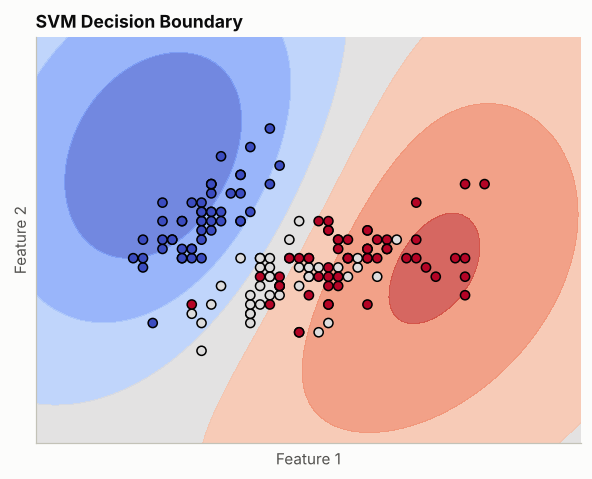

In [5]:
# BOOK CODE: Introduction to SVMs -- visualizing SVM decision boundaries (pp. 162-163)
# Load the libraries
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

# Create a mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Adjust the input to match the expected number of features
# (use all four features for prediction, but only visualize the first two)
grid_points = np.c_[
    xx.ravel(), yy.ravel(),
    np.zeros((xx.ravel().shape[0], 2))
]

# Plot decision boundaries using DecisionBoundaryDisplay
fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points[:, :2],
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)

# Plot the data points
ax.scatter(
    X[:, 0], X[:, 1], c=y, edgecolors='k',
    marker='o', cmap=plt.cm.coolwarm
)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xticks(())
ax.set_yticks(())
plt.show()

**Output analysis.**

* **Accuracy 0.93, as in the book** (42 of 45 test flowers). Setosa is perfect; 2 versicolor are called virginica and 1 virginica is called versicolor.
  * In the styled table, the `accuracy` row repeats the accuracy in every column, so its "support" shows 0.93 rounded to 1, not a count. This quirk of turning the report dictionary into a DataFrame affects every styled report of the chapter.
* **MSE 0.20, as in the book.** The regression example treats the class codes 0, 1 and 2 as numbers and predicts them from sepal length and width only. An MSE of 0.20 means a typical error of about $\sqrt{0.20} \approx 0.45$ class units. Rounding the predictions to the nearest code gives an accuracy of 0.80 (extra (c)), below the classifier's 0.93, which also uses the petal features.
* **What Figure 7.2 really shows.** The listing passes `svm_regressor`, the *regression* model, to `DecisionBoundaryDisplay`, so the colours are the predicted class code (from about −0.3 to 2.1), not the certainty of a classifier:
  * blue regions are predicted near 0 (setosa), red regions near 2 (virginica), and the pale band in between is where the prediction is near 1;
  * the model was fitted on the two plotted features only, so the figure shows exactly what it does, not a "squashed" view of a higher-dimensional boundary;
  * the comment "use all four features for prediction" does not apply: the two zero columns of `grid_points` are cut off by `grid_points[:, :2]`, and `DecisionBoundaryDisplay` only uses that array to find the plot range before building its own 100 by 100 grid.

w = [1.139 0.356], b = -3.114, margin width 2/||w|| = 1.676 cm
support vectors: 2, their decision values: [-1.  1.]


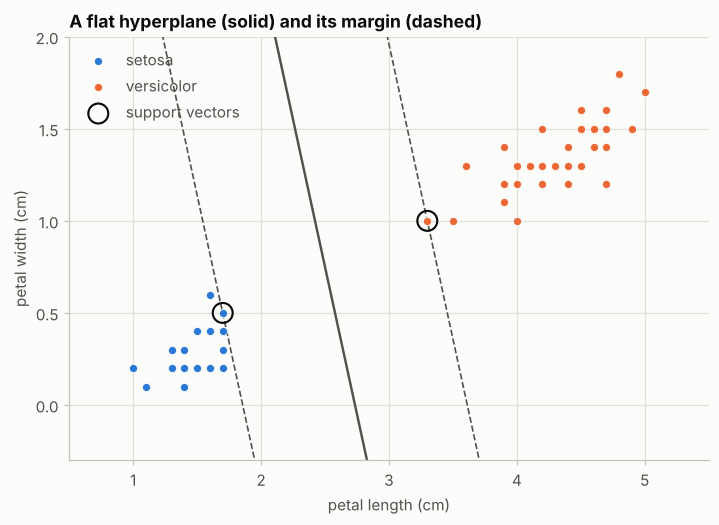

In [6]:
# EXTRA: (a) The margin and the support vectors, drawn and measured
# Setosa versus versicolor on the petal features: separable, so C=1000 gives (almost) a hard margin
two_classes = y_train < 2
X2, y2 = X_train[two_classes][:, 2:4], y_train[two_classes]
hard = SVC(kernel='linear', C=1000).fit(X2, y2)
w, b = hard.coef_[0], hard.intercept_[0]
print(f"w = {np.round(w, 3)}, b = {b:.3f}, margin width 2/||w|| = {2 / np.linalg.norm(w):.3f} cm")
print(f"support vectors: {hard.n_support_.sum()}, their decision values: {np.round(hard.decision_function(hard.support_vectors_), 3)}")

fig, ax = plt.subplots(figsize=(7.5, 5))
for label, color, name in [(0, PALETTE[0], "setosa"), (1, PALETTE[1], "versicolor")]:
    keep = y2 == label
    ax.scatter(X2[keep, 0], X2[keep, 1], s=28, color=color, edgecolor="white", lw=0.5, label=name, zorder=3)
ax.scatter(*hard.support_vectors_.T, s=170, facecolors="none", edgecolors=INK, lw=1.4, label="support vectors", zorder=4)
xs = np.linspace(0.5, 5.5, 200)
for level, style in [(0, "-"), (-1, "--"), (1, "--")]:
    ax.plot(xs, (level - b - w[0] * xs) / w[1], color=INK_SOFT, ls=style, lw=1.6 if level == 0 else 1.1)
ax.set_xlim(0.5, 5.5)
ax.set_ylim(-0.3, 2.0)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("A flat hyperplane (solid) and its margin (dashed)")
ax.legend(loc="upper left")
plt.show()

In [7]:
# EXTRA: (b) The dual solution -- the weight vector is a combination of the support vectors only
pair = y_train > 0                     # versicolor versus virginica: the classes that overlap
svm_pair = SVC(kernel='linear').fit(X_train[pair], y_train[pair])
w_from_dual = svm_pair.dual_coef_ @ svm_pair.support_vectors_      # sum of alpha_i * y_i * x_i
at_bound = np.isclose(np.abs(svm_pair.dual_coef_), svm_pair.C).sum()
print("coef_ equals sum(alpha_i y_i x_i) over the support vectors:", np.allclose(w_from_dual, svm_pair.coef_))
print(f"training points: {pair.sum()}, support vectors: {svm_pair.n_support_.sum()} "
      f"({at_bound} with alpha = C, i.e. inside the margin or misclassified)")
print(f"one-vs-one models in the 3-class SVC: {len(svm_classifier.intercept_)} (= 3 * 2 / 2)")

coef_ equals sum(alpha_i y_i x_i) over the support vectors: True
training points: 73, support vectors: 17 (12 with alpha = C, i.e. inside the margin or misclassified)
one-vs-one models in the 3-class SVC: 3 (= 3 * 2 / 2)


In [8]:
# EXTRA: (c) The regression example in classification terms
rounded = np.clip(np.round(y_pred_reg), 0, 2).astype(int)
print(f"SVR: support vectors {len(svm_regressor.support_)} of {len(X_train)}, epsilon = {svm_regressor.epsilon}")
print(f"SVR predictions range from {y_pred_reg.min():.2f} to {y_pred_reg.max():.2f}")
print(f"accuracy after rounding to the nearest class code: {accuracy_score(y_test, rounded):.3f}")
print(f"RMSE: {np.sqrt(mse):.3f} class units")

SVR: support vectors 70 of 105, epsilon = 0.1
SVR predictions range from -0.17 to 2.06
accuracy after rounding to the nearest class code: 0.800
RMSE: 0.451 class units


**Output analysis.**

* **(a)** The hard-margin SVM separates setosa from versicolor with the solid line, and the dashed lines bound the margin, **1.68 cm** wide.
  * Only **two** training flowers, circled, touch the margin, and their decision values are exactly $-1$ and $+1$. They alone determine the boundary: moving any other flower (without crossing the margin) changes nothing.
  * The boundary is a straight line, which is what "hyperplane" means.
* **(b)** For the overlapping pair (versicolor against virginica), `coef_` is exactly $\sum_i \alpha_i y_i x_i$ over the support vectors, as the dual says.
  * 17 of the 73 training flowers are support vectors, and 12 of them have $\alpha_i = C$: they sit inside the margin or on the wrong side, which is the soft margin at work.
  * The 3-class `SVC` contains three one-vs-one models.
* **(c)** The SVR keeps 70 of the 105 training points as support vectors, the points on or outside its $\varepsilon$-tube ($\varepsilon = 0.1$). Rounded to class codes, its predictions are right for 80% of the test flowers.
  * Treating class labels as numbers assumes that versicolor lies "between" setosa and virginica, which happens to be roughly true for Iris. With unordered labels it would make no sense; a classifier is the right tool.

---
## 2. Kernel functions and their applications

### Summary

* Kernel functions give SVMs their power on non-linear data. Mapping the data into a higher-dimensional space lets the SVM find a **linear** boundary there, which corresponds to a **non-linear** boundary in the original space. The book's image is an accordion that is stretched out to find the boundary and then squeezed back.
* **Getting ready** — the Iris data and split of recipe 1.
* **How to do it:**
  * `SVC(kernel='poly', degree=3)`: "slightly better" than the linear kernel (Figure 7.3).
  * `SVC(kernel='rbf')`: "a little worse" than the polynomial kernel, and the worst of the three (Figure 7.4), although only default parameters are used.
* **How it works:**
  * The **kernel trick** computes inner products in the high-dimensional space directly from the original data.
  * The book describes the three kernels:
    * linear — "maps the data linearly into a higher-dimensional space";
    * polynomial — for polynomial relationships between features;
    * RBF — uses a Gaussian function and handles complex relationships.
* **Visualizing kernel effects** — three SVMs refitted on the first two features (sepal length and width) and their decision regions side by side (Figure 7.5). They are "not very different at first glance".
* **There's more** — sigmoid and custom kernels.

### Theory: kernels as inner products

**The kernel trick.** In the dual (recipe 1), the training data appear only through inner products $x_i^\top x_j$, and so does the decision function. If a map $\varphi$ sends the data into a feature space, the SVM in that space needs only $k(x, z) = \langle \varphi(x), \varphi(z) \rangle$:

$$
f(x) = \sum_{i \in \text{SV}} \alpha_i y_i \, k(x_i, x) + b .
$$

A **kernel** is any function that equals such an inner product for some $\varphi$. Mercer's condition says this holds when every kernel matrix $K_{ij} = k(x_i, x_j)$ is positive semi-definite. The map $\varphi$ is never computed. This is what makes even an infinite-dimensional feature space usable.

**The kernels in scikit-learn** (their parameters are `gamma`, `degree` and `coef0` in `SVC`):

| Kernel | $k(x, z)$ | Feature space |
|---|---|---|
| `linear` | $x^\top z$ | the original space (no mapping at all) |
| `poly` | $(\gamma\, x^\top z + r)^d$ | all monomials up to degree $d$ when $r > 0$; only degree-$d$ monomials when $r = 0$ |
| `rbf` | $\exp(-\gamma \lVert x - z \rVert^2)$ | infinite-dimensional |
| `sigmoid` | $\tanh(\gamma\, x^\top z + r)$ | not always a valid kernel |

The defaults matter:

* `gamma='scale'` means $\gamma = 1 / (p \cdot \operatorname{Var}(X))$, computed from the training data;
* `degree=3`;
* `coef0` $= r = 0$.

So the default polynomial kernel is **homogeneous**: with $d = 3$ it contains only cubic terms, and it cannot represent a boundary such as $x_1^2 + x_2^2 = c$. Extra (c) shows the consequence.

**Reading the RBF kernel.** $k(x, z)$ is 1 when $x = z$ and decays with distance. The decision function is a weighted sum of Gaussian bumps centred on the support vectors, and $\gamma$ sets their width: a large $\gamma$ gives narrow bumps and wiggly boundaries, a small $\gamma$ a smooth, almost linear boundary. The RBF kernel does not involve a normal *distribution*; it only shares its bell shape.

**Precision to the text.** The linear kernel does not map the data anywhere: it is the plain inner product, so a linear SVM works in the original feature space.

In [9]:
# BOOK CODE: Kernel functions and their applications -- getting ready (p. 165)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [10]:
# BOOK CODE: Kernel functions and their applications -- how to do it: polynomial kernel (pp. 165-166)
# Load the model
svm_poly = SVC(kernel='poly', degree=3)

# Train the model
svm_poly.fit(X_train, y_train)

# Make predictions
y_pred_poly = svm_poly.predict(X_test)

# Evaluate the model
accuracy_poly = accuracy_score(y_test, y_pred_poly)
report_poly = classification_report(
    y_test, y_pred_poly, output_dict=True)
report_df_poly = pd.DataFrame(report_poly).transpose()

# Stylize the DataFrame
styled_df_poly = (report_df_poly
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
styled_df_poly

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


In [11]:
# BOOK CODE: Kernel functions and their applications -- how to do it: RBF kernel (pp. 167-168)
# Load the model
svm_rbf = SVC(kernel='rbf')

# Train the model
svm_rbf.fit(X_train, y_train)

# Make predictions
y_pred_rbf = svm_rbf.predict(X_test)

# Evaluate the model
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
report_rbf = classification_report(
    y_test, y_pred_rbf, output_dict=True)
report_df_rbf = pd.DataFrame(report_rbf).transpose()

# Stylize the DataFrame
styled_df_rbf = (report_df_rbf
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
styled_df_rbf

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


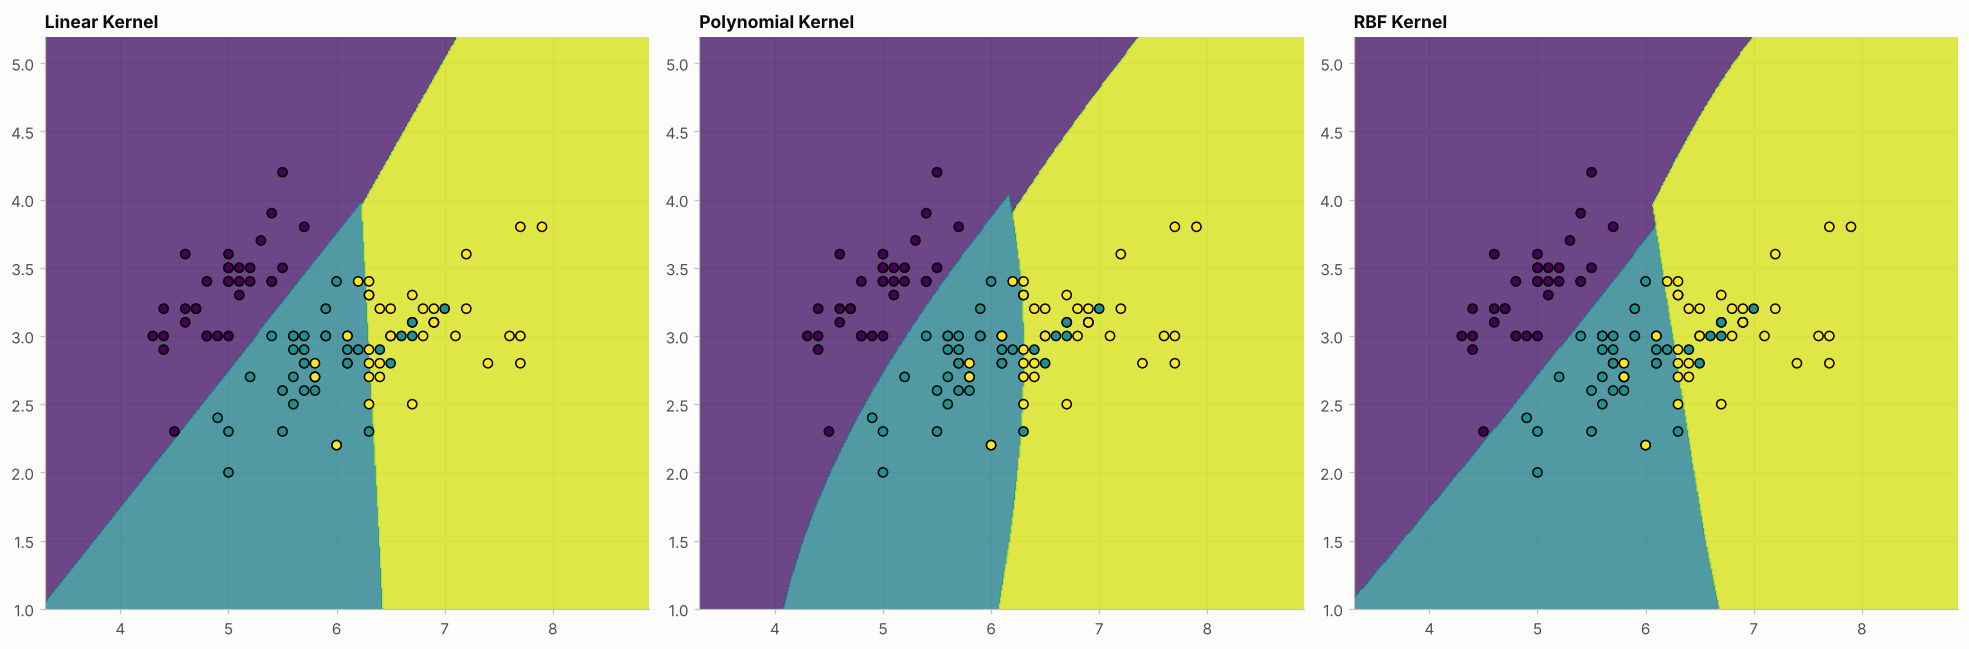

In [12]:
# BOOK CODE: Kernel functions and their applications -- visualizing kernel effects (pp. 168-170)
# Create a mesh grid
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Use only the first two features for prediction
X_train_2d = X_train[:, :2]

# Train new SVM models using only the first two features
svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

# Predict class probabilities across the grid for each kernel using only the first two features
Z_linear = svm_linear_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_poly = svm_poly_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_rbf = svm_rbf_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_linear = Z_linear.reshape(xx.shape)
Z_poly = Z_poly.reshape(xx.shape)
Z_rbf = Z_rbf.reshape(xx.shape)

# Plot the decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].contourf(xx, yy, Z_linear, alpha=0.8)
axes[0].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[0].set_title("Linear Kernel")
axes[1].contourf(xx, yy, Z_poly, alpha=0.8)
axes[1].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[1].set_title("Polynomial Kernel")
axes[2].contourf(xx, yy, Z_rbf, alpha=0.8)
axes[2].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[2].set_title("RBF Kernel")
plt.tight_layout()
plt.show()

**Output analysis.**

* **The book's ranking reproduces on this split:**

  | Kernel | Test accuracy | Correct (of 45) | Support vectors |
  |---|---|---|---|
  | polynomial (degree 3) | 0.96 | 43 | 14 |
  | linear (recipe 1) | 0.93 | 42 | 21 |
  | RBF | 0.91 | 41 | 48 |

  The three kernels differ by one flower each. Extra (b) checks whether that difference is real.
* **The book's inference** — that the data "probably has a structure that is better represented" with polynomial feature combinations — rests on this one-flower difference.
* **Figure 7.5** uses only sepal length and width, on which versicolor and virginica overlap heavily.
  * The three panels look alike because no kernel can separate those two species with these features.
  * On the test set the 2-D models score 0.80 (linear), 0.78 (polynomial) and 0.80 (RBF), far below the four-feature models.
  * The comment "predict class probabilities" is inaccurate: `predict` returns labels.

In [13]:
# EXTRA: (a) The kernel trick checked by hand, and the default gamma
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel

x_vec, z_vec = np.array([1.0, 2.0]), np.array([0.5, -1.0])
def phi(v):
    """Explicit feature map of the kernel (x.z + 1)^2 in two dimensions (6 coordinates)."""
    return np.array([1, np.sqrt(2) * v[0], np.sqrt(2) * v[1], v[0] ** 2, v[1] ** 2, np.sqrt(2) * v[0] * v[1]])
print(f"<phi(x), phi(z)> = {phi(x_vec) @ phi(z_vec):.4f}   (x.z + 1)^2 = {(x_vec @ z_vec + 1) ** 2:.4f}   "
      f"sklearn polynomial_kernel = {polynomial_kernel([x_vec], [z_vec], degree=2, gamma=1, coef0=1)[0, 0]:.4f}")
gamma_rbf = 1 / (X_train.shape[1] * X_train.var())
print(f"gamma='scale' on the Iris training set: 1 / (4 * Var(X)) = {gamma_rbf:.4f}")
print(f"RBF kernel by formula equals rbf_kernel: "
      f"{np.isclose(np.exp(-gamma_rbf * np.sum((X_train[0] - X_train[1]) ** 2)), rbf_kernel(X_train[:1], X_train[1:2], gamma=gamma_rbf)[0, 0])}")

<phi(x), phi(z)> = 0.2500   (x.z + 1)^2 = 0.2500   sklearn polynomial_kernel = 0.2500
gamma='scale' on the Iris training set: 1 / (4 * Var(X)) = 0.0645
RBF kernel by formula equals rbf_kernel: True


In [14]:
# EXTRA: (b) The three kernels over 50 cross-validation folds
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
for name, model in [("linear", SVC(kernel='linear')), ("polynomial (degree 3)", SVC(kernel='poly', degree=3)),
                    ("RBF", SVC(kernel='rbf'))]:
    scores = cross_val_score(model, iris.data, iris.target, cv=cv)
    print(f"{name:22s}: mean accuracy {scores.mean():.3f} (std {scores.std():.3f}) over {len(scores)} folds")

linear                : mean accuracy 0.977 (std 0.029) over 50 folds
polynomial (degree 3) : mean accuracy 0.960 (std 0.035) over 50 folds
RBF                   : mean accuracy 0.963 (std 0.032) over 50 folds


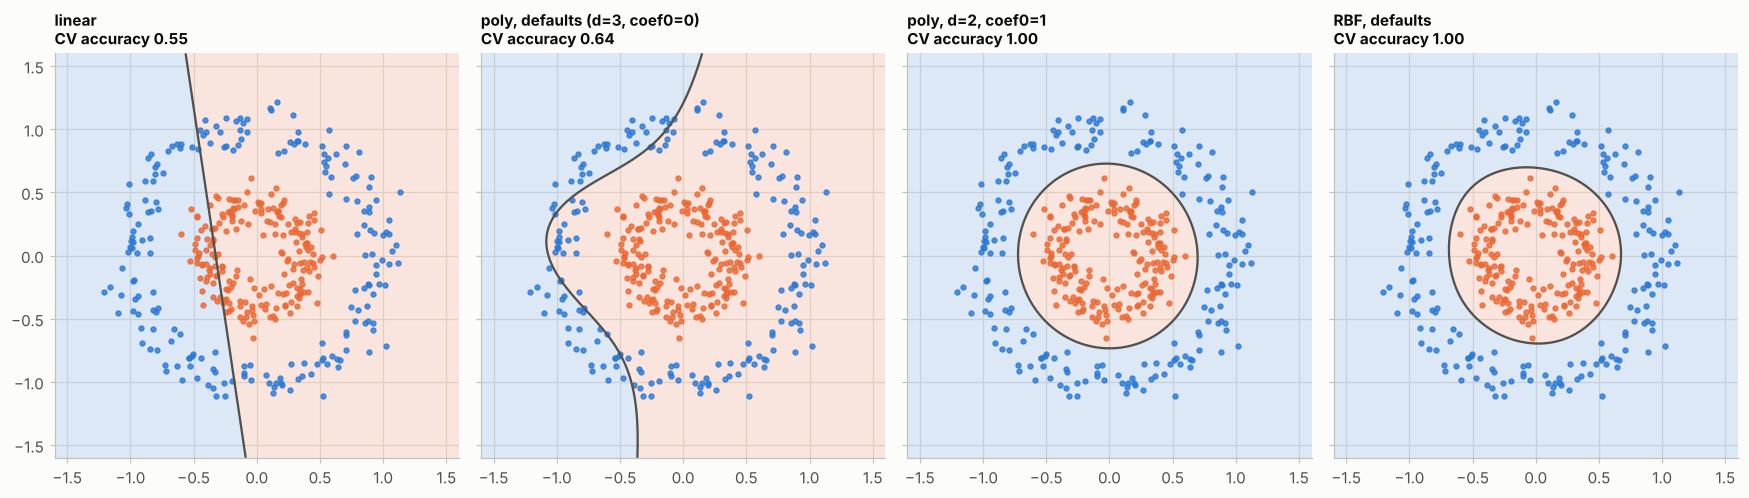

In [15]:
# EXTRA: (c) A dataset where the kernel decides everything -- two concentric circles
from sklearn.datasets import make_circles

X_circ, y_circ = make_circles(n_samples=400, noise=0.1, factor=0.4, random_state=0)
kernels = {
    "linear": SVC(kernel='linear'),
    "poly, defaults (d=3, coef0=0)": SVC(kernel='poly'),
    "poly, d=2, coef0=1": SVC(kernel='poly', degree=2, coef0=1),
    "RBF, defaults": SVC(kernel='rbf'),
}
gx, gy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, (name, model) in zip(axes, kernels.items()):
    cv_acc = cross_val_score(model, X_circ, y_circ, cv=5).mean()
    model.fit(X_circ, y_circ)
    Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, levels=[-0.5, 0.5, 1.5], colors=[PALETTE[0], PALETTE[1]], alpha=0.15)
    ax.contour(gx, gy, Z, levels=[0], colors=INK_SOFT, linewidths=1.5)
    for label, color in [(0, PALETTE[0]), (1, PALETTE[1])]:
        keep = y_circ == label
        ax.scatter(X_circ[keep, 0], X_circ[keep, 1], s=10, color=color, alpha=0.8)
    ax.set_title(f"{name}\nCV accuracy {cv_acc:.2f}", fontsize=10)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Output analysis.**

* **(a)** The six-coordinate feature map gives the same inner product (0.25) as the kernel formula, without the SVM ever needing those coordinates. On the Iris training set, `gamma='scale'` is 0.065.
* **(b) Over 50 folds the ranking reverses.**

  | Kernel | Mean CV accuracy | Standard deviation |
  |---|---|---|
  | linear | **0.977** | 0.029 |
  | RBF | 0.963 | 0.032 |
  | polynomial | 0.960 | 0.035 |

  The book's split favoured the polynomial kernel by one flower, but on average the linear kernel is the most accurate. Iris needs no kernel at all, and the differences are within one standard deviation. A single split of 45 flowers cannot rank models that differ by one or two percentage points.
* **(c) Where kernels matter.** On two concentric circles:
  * no straight line works: the linear kernel scores 0.55 (CV), near chance;
  * the **default polynomial kernel fails too** (0.64). With `coef0=0` and `degree=3` it contains only cubic terms, an odd function that cannot express "inside the circle";
  * a degree-2 polynomial with `coef0=1` contains $x_1^2 + x_2^2$ and separates the circles perfectly (1.00), as does the RBF kernel.

  This is the book's accordion: in the space of $(x_1, x_2, x_1^2 + x_2^2)$ a flat plane separates the classes, and it projects back to a circle.

---
## 3. Tuning SVM parameters

### Summary

* Hyperparameter tuning improves the accuracy and robustness of SVMs. This recipe uses classic **grid search with cross-validation**.
* **Getting ready** — the Iris data and the same 70/30 split.
* **How to do it:**
  * Search a grid of `C` in {0.1, 1, 10}, `kernel` in {linear, rbf, poly} and `degree` in {2, 3, 4} with `GridSearchCV(SVC(), param_grid, cv=5)`.
  * Print the best parameters and the best cross-validation score.
  * Refit an `SVC` with the best parameters and show its classification report (Figure 7.6).
  * The results are "almost the same" as with the default parameters, which reflects how simple the dataset is. Random search is mentioned as an alternative.
* **How it works:**
  * grid search tries every combination, so its cost grows quickly with the grid;
  * a high `C` makes the model "less tolerant of misclassifications";
  * the kernel parameters (`degree`, `gamma`) shape the mapping.
* **Visualizing hyperparameter effects** — the cross-validation score of an RBF SVM for 10 values of `C` from $10^{-4}$ to $10^{4}$ (Figure 7.7). The book reads diminishing returns, with performance plateauing around $C = 10^1$.
* **There's more** — randomized search samples the space more efficiently.

### Theory: what `C` and `gamma` do, and how grid search chooses

**`C` sets the price of a margin violation** (recipe 1):

* **Small `C`:**
  * the margin is wide and many points become support vectors;
  * the boundary is smooth, so the model has high bias.
  * In the limit, the hinge loss hardly matters and the model may predict a single class everywhere.
* **Large `C`:**
  * the margin is narrow, and the model follows individual training points;
  * it has low bias and high variance.

**`gamma` sets the reach of the RBF kernel** (recipe 2):

* **Small `gamma`:** wide bumps, an almost linear boundary.
* **Large `gamma`:** narrow bumps around each support vector. In the extreme, the model memorizes the training set.

The two interact: a large `C` can compensate for a small `gamma`, and conversely. So they are tuned **together**, on logarithmic grids, after **standardizing** the features. The RBF kernel measures Euclidean distances, so a feature with a large range would dominate.

**How `GridSearchCV` chooses:**

* It scores every combination in the grid by $k$-fold cross-validation and keeps the one with the highest mean score.
* When several candidates **tie**, it keeps the first one in the order of the grid. The grid is ordered alphabetically by parameter name (`C`, then `degree`, then `kernel`).
* Grid entries that a model ignores still count as separate candidates. `degree` only affects the polynomial kernel, so the book's 27 combinations contain only 15 different models.
* `best_score_` is the score of the winner, chosen because it scored highest, so it is an optimistic estimate (Chapter 4 showed nested cross-validation as the fix).

**Randomized search** draws a fixed number of combinations from distributions (for example log-uniform for `C` and `gamma`), so its cost no longer grows with the size of the grid.

In [16]:
# BOOK CODE: Tuning SVM parameters -- getting ready (pp. 171-172)
# Load the libraries
from sklearn.model_selection import (
    train_test_split, GridSearchCV)
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [17]:
# BOOK CODE: Tuning SVM parameters -- how to do it (pp. 172-173)
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters and score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

# Train a new model with the best hyperparameters
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred = best_model.predict(X_test)

# Evaluate the best model
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)
).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


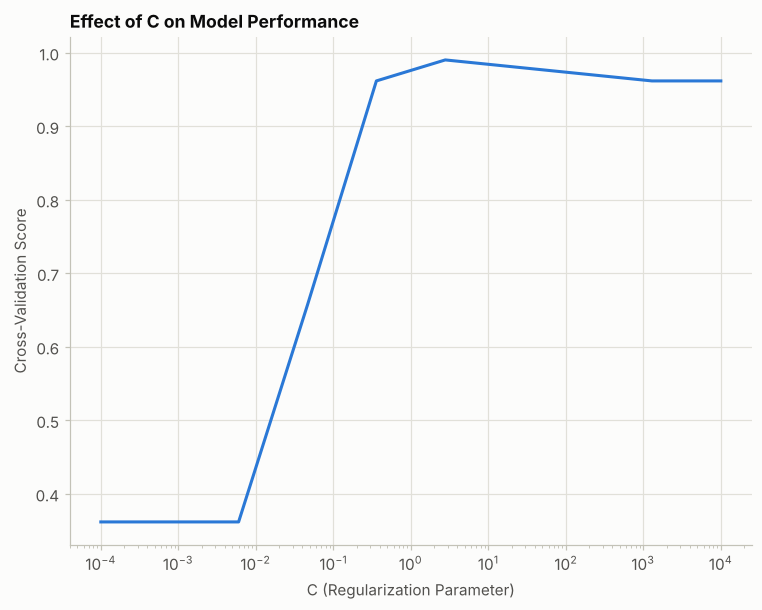

In [18]:
# BOOK CODE: Tuning SVM parameters -- visualizing hyperparameter effects (pp. 174-175)
# (np and plt come from the earlier recipes, as in the book)
# Perform a grid search with a range of C values for a specific kernel
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

# Plot the cross-validation scores against the C values
plt.figure(figsize=(8, 6))
plt.plot(
    grid_search_c.param_grid['C'],
    grid_search_c.cv_results_['mean_test_score']
)
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()

In [19]:
# EXTRA: (a) Inside the book's grid search -- redundant candidates, ties, and the tie-break
results = pd.DataFrame(grid_search.cv_results_)
results["model"] = [f"C={p['C']}, {p['kernel']}" + (f", degree={p['degree']}" if p['kernel'] == 'poly' else "")
                    for p in results["params"]]
print(f"candidates in the grid: {len(results)}, different models: {results['model'].nunique()}")
best = results[results["rank_test_score"] == 1]
print(f"candidates tied at the best score {best_score:.4f}: {len(best)}")
print(best[["model", "mean_test_score"]].to_string(index=False))

default_poly = SVC(kernel='poly').fit(X_train, y_train)
print(f"\ntest accuracy of the selected model {best_params}: {accuracy:.3f}")
print(f"test accuracy of the default polynomial SVC (recipe 2)      : {default_poly.score(X_test, y_test):.3f}")
print(f"\nC curve: {dict(zip(np.round(param_grid_c['C'], 4), np.round(grid_search_c.cv_results_['mean_test_score'], 3)))}")
print(f"share of the largest class in the training set: {np.bincount(y_train).max() / len(y_train):.3f}")

candidates in the grid: 27, different models: 15
candidates tied at the best score 0.9905: 8
                model  mean_test_score
C=0.1, poly, degree=4         0.990476
          C=1, linear         0.990476
  C=1, poly, degree=2         0.990476
          C=1, linear         0.990476
          C=1, linear         0.990476
            C=10, rbf         0.990476
            C=10, rbf         0.990476
            C=10, rbf         0.990476

test accuracy of the selected model {'C': 0.1, 'degree': 4, 'kernel': 'poly'}: 0.933
test accuracy of the default polynomial SVC (recipe 2)      : 0.956

C curve: {np.float64(0.0001): np.float64(0.362), np.float64(0.0008): np.float64(0.362), np.float64(0.006): np.float64(0.362), np.float64(0.0464): np.float64(0.657), np.float64(0.3594): np.float64(0.962), np.float64(2.7826): np.float64(0.99), np.float64(21.5443): np.float64(0.981), np.float64(166.8101): np.float64(0.971), np.float64(1291.5497): np.float64(0.962), np.float64(10000.0): np.float64(0.96

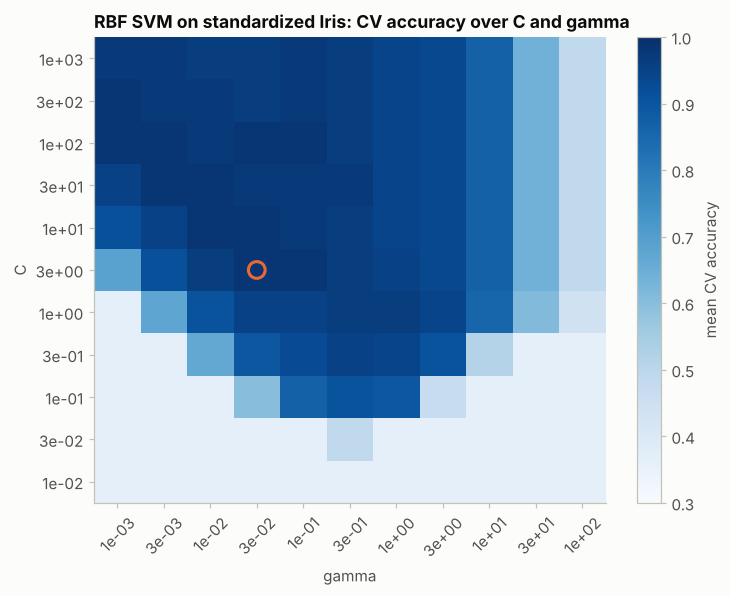

best CV accuracy 0.981, reached by 11 (C, gamma) pairs
test accuracy of those tied pairs: from 0.889 to 0.956


In [20]:
# EXTRA: (b) C and gamma tuned together (standardized features), as a heatmap
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

C_grid, gamma_grid = np.logspace(-2, 3, 11), np.logspace(-3, 2, 11)
search_rbf = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')),
                          {"svc__C": C_grid, "svc__gamma": gamma_grid},
                          cv=StratifiedKFold(5, shuffle=True, random_state=0))
search_rbf.fit(X_train, y_train)
scores = search_rbf.cv_results_["mean_test_score"].reshape(len(C_grid), len(gamma_grid))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
image = ax.imshow(scores, origin="lower", cmap="Blues", vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(gamma_grid)), [f"{g:.0e}" for g in gamma_grid], rotation=45)
ax.set_yticks(range(len(C_grid)), [f"{c:.0e}" for c in C_grid])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.grid(False)
best_i, best_j = np.unravel_index(np.argmax(scores), scores.shape)
ax.scatter(best_j, best_i, marker="o", s=120, facecolors="none", edgecolors=PALETTE[1], lw=2)
fig.colorbar(image, ax=ax, label="mean CV accuracy")
ax.set_title("RBF SVM on standardized Iris: CV accuracy over C and gamma")
plt.show()

tied = search_rbf.cv_results_["rank_test_score"] == 1
tied_params = [search_rbf.cv_results_["params"][i] for i in np.flatnonzero(tied)]
tied_test = [search_rbf.best_estimator_.set_params(**p).fit(X_train, y_train).score(X_test, y_test) for p in tied_params]
print(f"best CV accuracy {search_rbf.best_score_:.3f}, reached by {tied.sum()} (C, gamma) pairs")
print(f"test accuracy of those tied pairs: from {min(tied_test):.3f} to {max(tied_test):.3f}")

**Output analysis.**

* **The printed result:** best parameters `{'C': 0.1, 'degree': 4, 'kernel': 'poly'}` with a cross-validation score of **0.99**; the refitted model scores **0.93** on the test set, the same as the default linear SVC of recipe 1.
* **(a) Why those parameters?** The 27 candidates contain only 15 different models, and **8 candidates tie** at the best score (0.9905, one misclassified flower in 105).
  * The tied candidates include linear SVMs with `C=1`, RBF SVMs with `C=10`, and polynomial kernels of degree 2 and 4.
  * `GridSearchCV` keeps the first in grid order, so `C=0.1, degree=4, poly` wins by alphabetical accident rather than by merit.
  * On the test set, the selected model (0.933) is *worse* than the default polynomial SVC of recipe 2 (0.956). The book's "almost the same" is accurate. On 105 training flowers the tuning cannot separate models that differ by one flower.
* **The C curve (Figure 7.7):**
  * Below $C \approx 0.006$ the score is **0.362**, exactly the share of versicolor (38 of 105) in the training set: with such a weak penalty on errors the SVM predicts the same class everywhere.
  * The score rises steeply, peaks at **0.990 near $C \approx 2.8$**, then *declines* slightly (0.981, 0.971, 0.962) as a large `C` starts to fit individual training points.
  * So rather than a plateau around $10^1$, there is an optimum between $10^0$ and $10^1$, followed by mild overfitting.
* **(b) Tuning `C` and `gamma` together:**
  * The heatmap shows a broad diagonal ridge of good models: a small `gamma` needs a large `C`, and conversely. Very large `gamma` (bumps narrower than the gaps between flowers) or a tiny `C` collapses to the 0.36 baseline.
  * The best cross-validation accuracy (0.981) is reached by many `(C, gamma)` pairs, whose test accuracies range from 0.89 to about 0.96.
  * With 105 training flowers, the choice among them is essentially random. A broad ridge, not a single "best" point, is the useful finding.

---
## 4. SVMs in high-dimensional spaces

### Summary

* SVMs are presented as particularly effective on **high-dimensional ("wide")** data, where the number of features is large compared to the number of samples. The book's example is a rare event measured by several powerful instruments.
* **Getting ready** — `make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)`, split 70/30.
* **How to do it** — `SVC(kernel='linear')` with default parameters and a styled classification report (Figure 7.8). The book notes that the defaults "did not elicit the strongest performance".
* **How it works:**
  * SVMs handle high-dimensional data "by leveraging kernel functions";
  * the linear kernel suits linearly separable data or many features, and non-linear kernels suit non-linearly separable data.
* **Visualizing high-dimensional data** — a PCA projection onto two components, coloured by class (Figure 7.9). The classes look "quite messy", hard for a linear classifier to separate.
* **There's more** — $L_1$ and $L_2$ regularization help against overfitting in high dimensions.

### Theory: when there are more features than samples

**Perfect training accuracy is guaranteed, and meaningless.** With $p$ features, any $n \le p + 1$ points in general position can be split in every possible way by a hyperplane (Cover's theorem). Here the training set has 700 samples in 1,000 dimensions, so the classes are always linearly separable, whatever the labels. A linear SVM will reach 100% training accuracy even on pure noise. The question is only how well its margin generalizes.

**Why SVMs can still work.** Generalization bounds for SVMs depend on the margin relative to the spread of the data (roughly $R^2/\rho^2$ for data in a ball of radius $R$ separated with margin $\rho$), not on the number of features. A wide margin in a high-dimensional space can generalize well. The capacity control comes from the margin and the penalty `C`, not from the kernel, as the book suggests.

**What `make_classification` builds:**

* the informative features are Gaussian clusters placed at the vertices of a 50-dimensional hypercube, **two clusters per class** by default;
* so each class is a mixture of distant clusters, a structure that a single hyperplane cannot follow;
* the other 950 features are pure noise.

**Remedies when $p \gg n$:**

* **A stronger penalty** (smaller `C`).
* **An $L_1$ penalty.** `LinearSVC(penalty='l1', dual=False)` sets most weights to zero and so selects features. (`SVC` only supports the $L_2$ penalty.)
* **Univariate feature selection** (`SelectKBest`) inside a pipeline. It only works if each informative feature differs between the classes on its own.
* **A non-linear kernel**, if the class structure is not linear.

**PCA for visualization.** The first two principal components show the directions of largest *variance*, not the directions that separate the classes. With 1,000 features of similar variance, two components capture only a small share of the total, and the class information can be invisible in that projection even when a classifier can find it.

In [21]:
# BOOK CODE: SVMs in high-dimensional spaces -- getting ready (pp. 176-177)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd
import numpy as np

# Create a synthetic high-dimensional dataset
X, y = make_classification(
    n_samples=1000, n_features=1000,
    n_informative=50, n_redundant=0, random_state=2024
)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [22]:
# BOOK CODE: SVMs in high-dimensional spaces -- how to do it (pp. 177-178)
# Load the model
svm_model = SVC(kernel='linear')

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)
).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


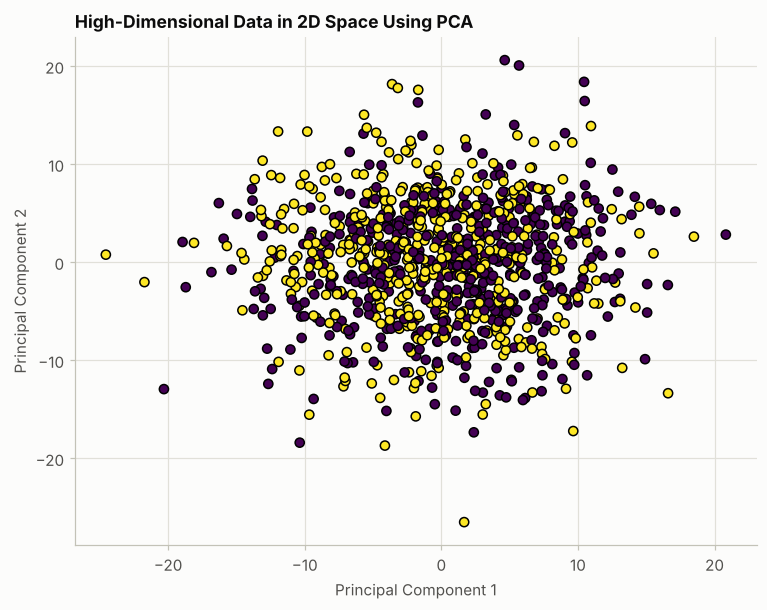

In [23]:
# BOOK CODE: SVMs in high-dimensional spaces -- visualizing high-dimensional data (pp. 178-179)
# Import PCA from sklearn.decomposition
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensionality
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the reduced data
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1], c=y,
    edgecolors='k', marker='o'
)
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [24]:
# EXTRA: (a) Diagnosing the linear SVM -- separable by construction, and a weak PCA picture
print(f"training accuracy: {svm_model.score(X_train, y_train):.3f} | test accuracy: {accuracy:.3f}")
print(f"support vectors: {svm_model.n_support_.sum()} of {len(X_train)} training samples")
print(f"variance explained by PC1 and PC2: {pca.explained_variance_ratio_.round(4)} "
      f"(together {pca.explained_variance_ratio_.sum():.1%})")

# Pure noise with random labels: the linear SVM still separates the training set perfectly
rng = np.random.default_rng(0)
noise_X, noise_y = rng.normal(size=(700, 1000)), rng.integers(0, 2, 700)
print(f"pure noise, random labels: training accuracy {SVC(kernel='linear').fit(noise_X, noise_y).score(noise_X, noise_y):.3f}")

training accuracy: 1.000 | test accuracy: 0.747
support vectors: 433 of 700 training samples
variance explained by PC1 and PC2: [0.0245 0.0212] (together 4.6%)
pure noise, random labels: training accuracy 1.000


In [25]:
# EXTRA: (b) Five alternatives, judged by 5-fold cross-validation on the training set and by the test set
import time
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
candidates = {
    "linear SVC, C=1 (book)": SVC(kernel='linear'),
    "linear SVC, C=0.001": SVC(kernel='linear', C=0.001),
    "L1 LinearSVC, C=0.01": LinearSVC(penalty='l1', dual=False, C=0.01, max_iter=5000),
    "SelectKBest(50) + linear SVC": make_pipeline(SelectKBest(f_classif, k=50), SVC(kernel='linear')),
    "RBF SVC (defaults)": SVC(kernel='rbf'),
}
rows = []
for name, model in candidates.items():
    start = time.perf_counter()
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv5)
    model.fit(X_train, y_train)
    rows.append({"model": name, "CV accuracy": round(cv_scores.mean(), 3),
                 "test accuracy": round(model.score(X_test, y_test), 3),
                 "non-zero weights": int(np.count_nonzero(model.coef_)) if name.startswith("L1") else ""})
print(pd.DataFrame(rows).to_string(index=False))

                       model  CV accuracy  test accuracy non-zero weights
      linear SVC, C=1 (book)        0.700          0.747                 
         linear SVC, C=0.001        0.729          0.773                 
        L1 LinearSVC, C=0.01        0.774          0.833               53
SelectKBest(50) + linear SVC        0.667          0.727                 
          RBF SVC (defaults)        0.859          0.883                 


**Output analysis.**

* **The book's linear SVM** scores **0.75** on the test set. Precision and recall are 0.77 for class 0 and 0.73 for class 1, so the errors are spread over both classes.
* **(a) Why:**
  * The training accuracy is a perfect 1.000, and 433 of the 700 training samples are support vectors. When almost two thirds of the data sit on or inside the margin, the margin carries little information.
  * As the theory predicts, the same linear SVM also reaches 1.000 training accuracy on pure noise with random labels: in 1,000 dimensions, 700 points can always be separated.
  * **The PCA picture is messy for a simple reason.** PC1 and PC2 explain only 2.4% and 2.1% of the variance (4.6% together), so the plot shows almost nothing of the data. The class information lives in 50 informative directions that the top-variance directions do not single out.
* **(b) What helps** (5-fold CV on the training set, then the test set):

  | Model | CV accuracy | Test accuracy |
  |---|---|---|
  | linear SVC, `C=1` (book) | 0.70 | 0.75 |
  | linear SVC, `C=0.001` | 0.73 | 0.77 |
  | $L_1$ `LinearSVC`, `C=0.01` (53 non-zero weights) | 0.77 | 0.83 |
  | `SelectKBest(50)` + linear SVC | 0.67 | 0.73 |
  | **RBF SVC (defaults)** | **0.86** | **0.88** |

  * The **RBF kernel** is clearly best. Each class is made of two distant clusters, a non-linear structure, so here the kernel matters more than the dimension. This contradicts the rule of thumb that the linear kernel suits many features.
  * The **$L_1$ penalty** the book mentions in *There's more* helps: keeping about 50 weights matches the 50 informative features.
  * **Univariate selection fails.** It picks the features whose class means differ most, but with two clusters per class those differences are weak, and the selected set misses informative features. Feature selection is not automatically safe.

---
## 5. Evaluating SVM models

### Summary

* Evaluating SVMs tells us how well they generalize. This recipe uses accuracy, precision, recall and **ROC curves**.
* **Getting ready** — the Breast Cancer data, split 70/30 (`random_state=2024`), unscaled. "We do not need to prepare our data any differently to utilize ROC curves."
* **How to do it:**
  * Fit `SVC(kernel='linear', probability=True)`, then get predictions and probabilities.
  * Show a styled classification report (Figure 7.10). The book finds the performance substantially better than before, partly because the classes are easier to separate and the problem is binary.
  * Plot the ROC curve (Figure 7.11). The AUC is **98%**.
* **How it works** — the definitions of accuracy, precision, recall, F1, the ROC curve and the AUC, as in Chapter 6.
* **There's more** — choose the metric according to the cost of false positives and false negatives.

### Theory: SVM scores, probabilities, and scaling

**An SVM produces scores, not probabilities.** `decision_function` returns the signed distance-like score $f(x)$. To obtain probabilities, `SVC(probability=True)` uses **Platt scaling**:

1. it fits a sigmoid $P(y = 1 \mid x) = 1 / \big(1 + e^{A f(x) + B}\big)$ to scores obtained by an internal 5-fold cross-validation;
2. it refits the SVM on all the data.

Consequences:

* training costs about six fits instead of one;
* the internal folds are random, so results depend on `random_state`;
* `predict` (sign of $f$) and `predict_proba` (sigmoid of cross-validated scores) can disagree for points near the boundary.

scikit-learn 1.9 deprecated `probability=True` (it is removed in 1.11) in favour of `CalibratedClassifierCV(SVC(), ensemble=False)`, which does the same thing explicitly.

**The ROC curve does not need probabilities.** The ROC curve and its AUC depend only on the **ranking** of the scores (Chapter 6). Platt scaling is a monotone function of $f(x)$ when $A < 0$, so `decision_function` gives the same curve and AUC without any calibration.

**SVMs need scaled features.** The book's "no need to prepare our data any differently" holds for the ROC curve, not for the SVM:

* The penalty $\tfrac12 \lVert w \rVert^2$ and the RBF distances treat all features alike, so features in large units dominate.
* Poorly scaled data also make the libsvm solver converge much more slowly.
* The breast cancer features range from about 0.05 (smoothness) to over 2,000 (area).

In [26]:
# BOOK CODE: Evaluating SVM models -- getting ready (p. 181)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    classification_report, roc_curve, auc)
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [27]:
# BOOK CODE: Evaluating SVM models -- how to do it (pp. 181-182)
# NOTE: this listing never computes `accuracy`; the print below shows the value left by recipe 4
# (see the output analysis)
# Load the model
svm_model = SVC(kernel='linear', probability=True)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate the model
report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


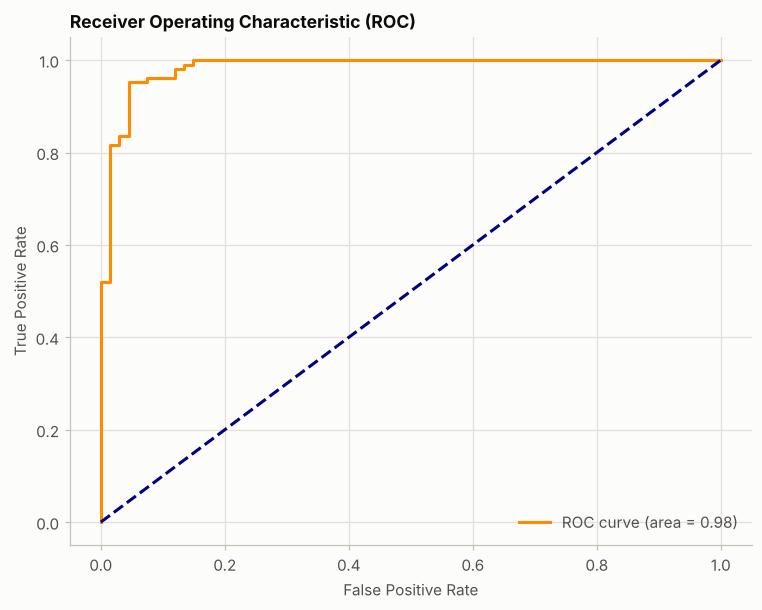

In [28]:
# BOOK CODE: Evaluating SVM models -- plot the ROC curve (p. 183)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr, color='darkorange', lw=2,
    label=f'ROC curve (area = {roc_auc:.2f})'
)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [29]:
# EXTRA: (a) The real accuracy, and probabilities versus decision scores
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score

print(f"accuracy printed by the listing (left over from recipe 4): {accuracy:.2f}")
print(f"actual accuracy of this SVM                              : {accuracy_score(y_test, y_pred):.3f}")
print(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["true malignant", "true benign"],
                   columns=["pred. malignant", "pred. benign"]))
scores_svm = svm_model.decision_function(X_test)
print(f"\nROC AUC from predict_proba     : {roc_auc_score(y_test, y_prob):.4f}")
print(f"ROC AUC from decision_function : {roc_auc_score(y_test, scores_svm):.4f}")
print(f"test points where predict and predict_proba >= 0.5 disagree: {int(((y_prob >= 0.5).astype(int) != y_pred).sum())}")

accuracy printed by the listing (left over from recipe 4): 0.75
actual accuracy of this SVM                              : 0.947
                pred. malignant  pred. benign
true malignant               63             4
true benign                   5            99

ROC AUC from predict_proba     : 0.9841
ROC AUC from decision_function : 0.9841
test points where predict and predict_proba >= 0.5 disagree: 2


In [30]:
# EXTRA: (b) What scaling does to an SVM -- accuracy, AUC and fitting time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV

rows = []
for name, model in [("linear, raw features (book)", SVC(kernel='linear')),
                    ("linear, standardized", make_pipeline(StandardScaler(), SVC(kernel='linear'))),
                    ("RBF, raw features", SVC(kernel='rbf')),
                    ("RBF, standardized", make_pipeline(StandardScaler(), SVC(kernel='rbf')))]:
    start = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - start
    rows.append({"model": name, "accuracy": round(model.score(X_test, y_test), 3),
                 "ROC AUC": round(roc_auc_score(y_test, model.decision_function(X_test)), 4),
                 "fit faster than raw linear": None, "_seconds": seconds})
table = pd.DataFrame(rows)
table["fit faster than raw linear"] = (table["_seconds"].iloc[0] / table["_seconds"]).round(0).astype(int).astype(str) + "x"
print(table.drop(columns="_seconds").to_string(index=False))

# The replacement for probability=True recommended by scikit-learn 1.9
calibrated = CalibratedClassifierCV(make_pipeline(StandardScaler(), SVC(kernel='linear')), ensemble=False)
calibrated.fit(X_train, y_train)
print(f"\nCalibratedClassifierCV(..., ensemble=False): ROC AUC {roc_auc_score(y_test, calibrated.predict_proba(X_test)[:, 1]):.4f}")

                      model  accuracy  ROC AUC fit faster than raw linear
linear, raw features (book)     0.947   0.9841                         1x
       linear, standardized     0.982   0.9989                       942x
          RBF, raw features     0.918   0.9763                      1293x
          RBF, standardized     0.982   0.9987                       542x

CalibratedClassifierCV(..., ensemble=False): ROC AUC 0.9989


**Output analysis.**

* **The printed "Accuracy: 0.75" is wrong, in the book's code as well.** The listing never computes `accuracy`, so it prints the value left by the high-dimensional recipe (0.75).
  * The SVM's real accuracy is **0.947** (162 of 171 tumours), which is what the classification report shows.
  * In a fresh session, without the previous recipe, the same line would raise a `NameError`. The listing does not even import `accuracy_score`.
* **The ROC curve** reproduces the book: **AUC 0.98** (0.984). The text calls the curve yellow; it is drawn in dark orange.
* **(a)** The AUC from `decision_function` is identical to the one from `predict_proba`. Platt scaling preserves the ranking, so the probabilities were not needed for this curve.
  * For **2 test tumours**, `predict` and the 0.5 threshold of `predict_proba` disagree: the inconsistency described in the theory section, because the sigmoid is fitted on cross-validated scores.
  * The confusion matrix shows 4 malignant tumours called benign and 5 benign tumours called malignant.
* **(b) Scaling matters more than the kernel:**
  * Standardizing raises the linear SVM from 0.947 to **0.982** accuracy and from 0.984 to **0.999** AUC.
  * It speeds up the fit by two to three orders of magnitude (the exact factor depends on the machine): the slow, unscaled linear fit is what makes this listing and exercise 2 take long.
  * Without scaling, the RBF kernel is even worse (0.918) than the linear one, because the area features dominate its distances.
  * The calibrated replacement for `probability=True` gives probabilities with an AUC of 0.999 on standardized features.

---
## 6. Practical exercises with SVMs

### Summary

The chapter ends with three exercises (pp. 185–186), each a list of steps; the solutions are in the book's repository.

1. **Building a simple SVM classifier** on Iris.
2. **Tuning SVM parameters with grid search** on the Breast Cancer data, with the grid of recipe 3.
3. **Visualizing SVM decision boundaries** of an SVM trained on a synthetic two-feature dataset (`make_classification`).

The official notebook stores no outputs. The solutions below are run as published.

### Theory: what the exercises show

* **Exercise 1** repeats recipe 1: a linear SVC on the same Iris split, printed as plain text.
* **Exercise 2** runs recipe 3's grid on the Breast Cancer data **without scaling**.
  * The linear and polynomial kernels on raw features are slow to fit (recipe 5), so this grid of 27 candidates times 5 folds takes about a minute.
  * Recipe 5 suggests that a pipeline with `StandardScaler` will be both faster and more accurate; extra (a) checks it.
* **Exercise 3** uses an RBF SVC on two features. Its decision boundary $f(x) = 0$ is curved, and the margins $f(x) = \pm 1$ show the band in which the support vectors lie (extra (b)). The comment "predict class probabilities" again calls `predict`, which returns labels.

In [31]:
# BOOK CODE: Exercise 1 -- building a simple SVM classifier (official solution)
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a SVM classifier
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(report)

Accuracy: 0.93
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.91      0.83      0.87        12
           2       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.92      0.92        45
weighted avg       0.93      0.93      0.93        45



In [32]:
# BOOK CODE: Exercise 2 -- tuning SVM parameters with grid search (official solution; about a minute)
# Load the libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define a hyperparameter for grid search
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Train a new model with the best hyperparameters
best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred_best = best_model.predict(X_test)

# Evaluate the best model
accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = classification_report(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.2f}")
print("Best Model Classification Report:")
print(report_best)

Best Model Accuracy: 0.95
Best Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        67
           1       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



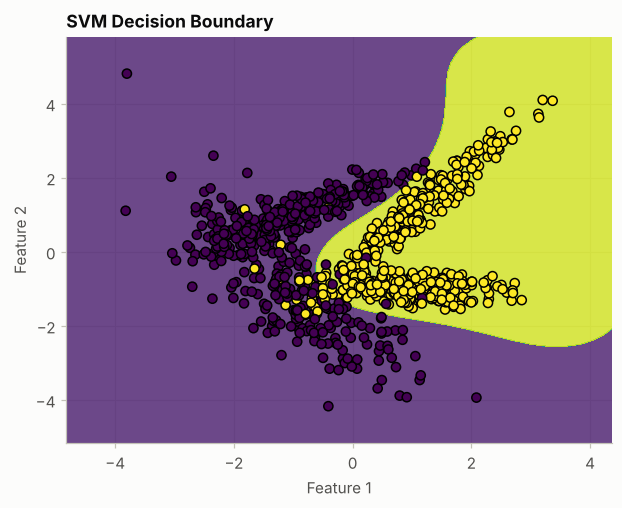

In [33]:
# BOOK CODE: Exercise 3 -- visualizing SVM decision boundaries (official solution)
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Create a synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train an SVM model
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class probabilities across the grid
Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Output analysis.**

* **Exercise 1:** accuracy 0.93, the same model and report as recipe 1.
* **Exercise 2:**
  * The grid search selects `{'C': 1, 'degree': 2, 'kernel': 'linear'}`. `degree` is irrelevant for the linear kernel; it is the first value of the grid.
  * The best model scores **0.95** on the test set (0.947, 9 errors in 171).
  * Most of the minute goes into the linear and polynomial fits on unscaled features.
* **Exercise 3:** a smooth curved boundary separates the two classes (purple and yellow in Matplotlib's default colour map). The two clouds overlap, so some points remain on the wrong side. The solution does not print an accuracy; extra (b) does.

In [34]:
# EXTRA: (a) Exercise 2 with a StandardScaler in a pipeline -- the same grid, much faster and more accurate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_bc_train, X_bc_test, y_bc_train, y_bc_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=2024)
start = time.perf_counter()
scaled_search = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                             {f"svc__{key}": values for key, values in param_grid.items()}, cv=5)
scaled_search.fit(X_bc_train, y_bc_train)
seconds = time.perf_counter() - start
print(f"exercise 2 (raw features)  : best {grid_search.best_params_}, CV {grid_search.best_score_:.3f}, "
      f"test accuracy {accuracy_best:.3f}")
print(f"with StandardScaler        : best { {k.replace('svc__', ''): v for k, v in scaled_search.best_params_.items()} }, "
      f"CV {scaled_search.best_score_:.3f}, test accuracy {scaled_search.score(X_bc_test, y_bc_test):.3f}")
print(f"the scaled search took {seconds:.1f} s")

exercise 2 (raw features)  : best {'C': 1, 'degree': 2, 'kernel': 'linear'}, CV 0.962, test accuracy 0.947
with StandardScaler        : best {'C': 0.1, 'degree': 2, 'kernel': 'linear'}, CV 0.977, test accuracy 0.982
the scaled search took 0.8 s


accuracy: train 0.960, test 0.977; support vectors: 118 of 700


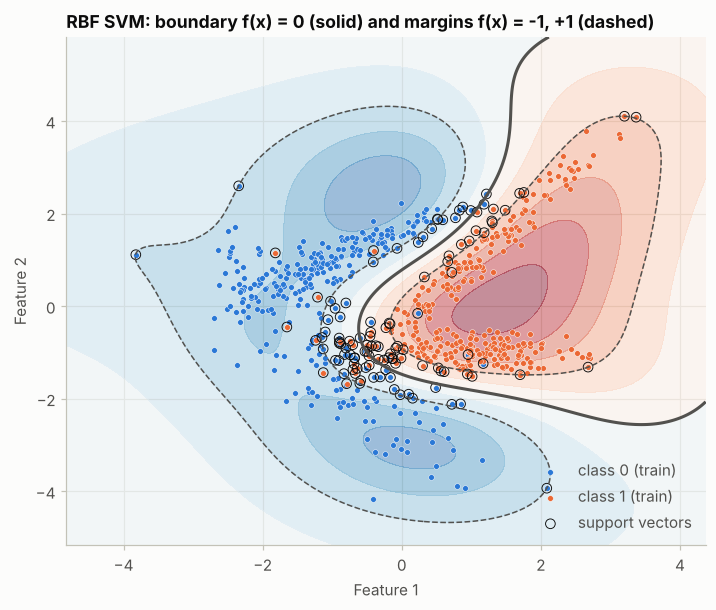

In [35]:
# EXTRA: (b) Exercise 3 with the decision function -- boundary, margins and support vectors
print(f"accuracy: train {svm_model.score(X_train, y_train):.3f}, test {svm_model.score(X_test, y_test):.3f}; "
      f"support vectors: {svm_model.n_support_.sum()} of {len(X_train)}")
gx, gy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
F = svm_model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contourf(gx, gy, F, levels=np.linspace(-3, 3, 13), cmap="RdBu_r", alpha=0.45, extend="both")
ax.contour(gx, gy, F, levels=[-1, 0, 1], colors=INK_SOFT, linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
for label, color, name in [(0, PALETTE[0], "class 0"), (1, PALETTE[1], "class 1")]:
    keep = y_train == label
    ax.scatter(X_train[keep, 0], X_train[keep, 1], s=14, color=color, edgecolor="white", lw=0.3, label=f"{name} (train)")
ax.scatter(*svm_model.support_vectors_.T, s=40, facecolors="none", edgecolors=INK, lw=0.6, label="support vectors")
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("RBF SVM: boundary f(x) = 0 (solid) and margins f(x) = -1, +1 (dashed)")
ax.legend(loc="lower right")
plt.show()

**Output analysis.**

* **(a) Exercise 2 with scaling:**
  * The same grid, run inside a `StandardScaler` pipeline, takes under a second instead of about a minute.
  * It selects a linear kernel with a smaller `C` (0.1), and it is more accurate: CV accuracy 0.977 against 0.962, test accuracy **0.982** against 0.947.
  * As in recipe 5, scaling is the most effective "hyperparameter".
* **(b) The decision function:**
  * The solid curve $f(x) = 0$ is the boundary of the exercise's figure, and the dashed curves $f(x) = \pm 1$ bound the margin.
  * The circled support vectors (118 of 700) are the training points on or inside the margin, or on the wrong side. Most lie where the two clouds overlap; the others sit on the dashed margin curves.
  * The model scores 0.96 on the training set and 0.977 on the test set.

---
## Decision guide: setting up an SVM

| Situation | Choice | Notes |
|---|---|---|
| Any SVM | `make_pipeline(StandardScaler(), SVC(...))` | scaling changes the model and can speed up the fit by orders of magnitude |
| Many samples, linear problem | `LinearSVC` (or `SGDClassifier(loss='hinge')`) | scales to large `n`; `SVC` is quadratic or worse in `n` |
| Non-linear boundary, moderate `n` | `SVC(kernel='rbf')`, tune `C` and `gamma` together on log grids | look for a ridge of good values, not a single point |
| Polynomial structure | `SVC(kernel='poly', degree=d, coef0=1)` | the default `coef0=0` keeps only degree-$d$ terms |
| Many features, few samples | a smaller `C`, `LinearSVC(penalty='l1', dual=False)`, or an RBF kernel | a perfect training score means nothing when $p > n$ |
| Probabilities needed | `CalibratedClassifierCV(SVC(), ensemble=False)` | replaces `SVC(probability=True)`, deprecated in 1.9 |
| ROC curve or AUC only | `decision_function` | no calibration needed: the AUC only depends on the ranking |
| Regression | `SVR` (`epsilon`, `C`, kernel) | errors within `epsilon` are ignored |

## Chapter summary and key takeaways

| Recipe | Main tools | Key idea |
|---|---|---|
| Introduction to SVMs | `SVC`, `SVR`, `DecisionBoundaryDisplay` | The widest flat margin; only the support vectors matter; hinge loss plus an $L_2$ penalty |
| Kernel functions | `kernel`, `degree`, `gamma`, `coef0` | A kernel is an inner product in a feature space that is never computed |
| Tuning SVM parameters | `GridSearchCV`, `C`, `gamma` | `C` and `gamma` interact; ties and ignored parameters make "the best" grid point fragile |
| High-dimensional spaces | `SVC`, `LinearSVC(penalty='l1')`, `PCA` | With $p > n$ the training set is always separable; the margin, the penalty and the kernel decide generalization |
| Evaluating SVM models | `decision_function`, `roc_curve`, `CalibratedClassifierCV` | SVMs give scores; the AUC needs no probabilities; scale the features |
| Practical exercises | `SVC`, `GridSearchCV`, `make_classification` | Scaling makes the grid search faster and better; the margins show where the support vectors lie |

**Key takeaways**

1. An SVM maximizes the margin of a **flat** hyperplane. Kernels make that hyperplane live in a feature space where it can look curved in the original one, and the solution depends only on the support vectors.
2. The kernel choice matters when the class structure is non-linear (concentric circles, clustered classes), and hardly at all on Iris. Check kernel defaults: the default polynomial kernel is homogeneous.
3. Tune `C` and `gamma` together on standardized features, and treat the result as a region of good values. On small datasets, several candidates tie and the test set cannot tell them apart.
4. With more features than samples, a perfect training accuracy is guaranteed and says nothing. Judge by cross-validation, and consider a stronger penalty, an $L_1$ model or a non-linear kernel.
5. Always scale the features for an SVM. Use `decision_function` for ROC curves, and `CalibratedClassifierCV` when real probabilities are needed.

**Book (scikit-learn 1.5) vs. the version used here — notes from the reproduction**

* All listings and the three official exercise solutions run on scikit-learn 1.9.1, and every printed result reproduces: 93% (recipe 1), MSE 0.20, AUC 0.98.
* **`SVC(probability=True)`** (recipe 5) is deprecated since scikit-learn 1.9 and will be removed in 1.11. The setup cell silences the warning. The replacement, `CalibratedClassifierCV(SVC(), ensemble=False)`, is shown in extra 5(b).
* **A stale variable:** the evaluation listing prints `accuracy` without computing it, so the book's code prints the previous recipe's 0.75. The real accuracy is 0.947.
* Recipe 1's "decision boundary" listing passes the regression model (`SVR`) to `DecisionBoundaryDisplay`, so its colours are predicted class codes. Its extra zero columns are never used.
* The tuning listing uses `np` and `plt` from earlier recipes, and the evaluation listing never imports `accuracy_score`; the notebook runs them in order, as the book does.
* Precisions to the chapter text:
  * A hyperplane is flat, not "a non-linear line".
  * The linear kernel does not map the data into a higher-dimensional space.
  * The RBF feature space is infinite-dimensional, and the kernel is not a normal distribution.
  * Figure 7.2 shows an SVR fitted on the two plotted features, not a squashed view of a higher-dimensional boundary.
  * The C curve peaks near $C \approx 3$ and then declines, rather than plateauing around $10^1$.
  * The kernel ranking on the 45-flower test set (polynomial, linear, RBF) does not survive cross-validation, where the linear kernel is the most accurate.
  * In the high-dimensional recipe, the RBF kernel (0.88) beats the linear one (0.75).
  * Generalization in high dimensions comes from the margin and the penalty, not from "leveraging kernel functions".

## References

1. Sukup, J. (2025). *scikit-learn Cookbook* (3rd ed.). Packt Publishing. Code repository: <https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition>
2. Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297.
3. Boser, B. E., Guyon, I. M., & Vapnik, V. N. (1992). A training algorithm for optimal margin classifiers. *Proceedings of the 5th Annual Workshop on Computational Learning Theory*, 144–152.
4. Schölkopf, B., & Smola, A. J. (2002). *Learning with Kernels*. MIT Press.
5. Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing, 14*(3), 199–222.
6. Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In *Advances in Large Margin Classifiers*, 61–74. MIT Press.
7. Chang, C.-C., & Lin, C.-J. (2011). LIBSVM: A library for support vector machines. *ACM Transactions on Intelligent Systems and Technology, 2*(3), 27.
8. Hsu, C.-W., Chang, C.-C., & Lin, C.-J. (2003). *A Practical Guide to Support Vector Classification*. Technical report, National Taiwan University.
9. Cover, T. M. (1965). Geometrical and statistical properties of systems of linear inequalities with applications in pattern recognition. *IEEE Transactions on Electronic Computers, EC-14*(3), 326–334.
10. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
11. scikit-learn documentation: [Support Vector Machines](https://scikit-learn.org/stable/modules/svm.html) · [RBF SVM parameters](https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html) · [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)